# Collect Data

In [1]:
%pip install pandas numpy seaborn matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

In [3]:
import time
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv('final_data.csv')
df

,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP
0,4073,10597.4769,4800.2166,56.5923,1355.916,744,33.30,2.02232,40592.3314,3-BRSA-1024-SPS
1,3702,3245.1189,8032.5534,16.1271,386.394,744,33.30,2.02232,40592.3314,7-PRA-2-SPS
2,3563,0.0000,0.0000,0.0000,0.000,0,33.30,2.02232,40592.3314,7-BAN-2-SPS
3,4128,2116.3271,5439.4737,25.6074,613.536,714,33.30,2.02232,40592.3314,9-BRSA-999-SPS
4,3609,1978.3072,5187.5167,16.1911,387.928,712,33.30,2.02232,40592.3314,7-BAN-1-SPS
...,...,...,...,...,...,...,...,...,...,...
24521,14311,221.0590,4176.8396,0.8269,25.633,580,22.86,2.01722,40657.3157,7-PG-19D-RJS
24522,14562,253.8190,1296.9182,1.2978,40.232,661,22.86,2.01722,40657.3157,7-PG-12D-RJS
24523,14893,635.0981,1784.2771,1.9080,59.149,727,22.86,2.01722,40657.3157,7-PG-4-RJS
24524,14154,460.4175,4570.8658,1.3961,43.278,725,22.86,2.01722,40657.3157,7-PG-24D-RJS


In [5]:
from math import log

In [6]:
target_column = 'Petroleo'
ignore_columns = [
    'Nome_Poco_ANP'
]

In [7]:
sample_df = df.sample(frac=1, random_state=42)
sample_df.drop_duplicates(inplace=True)
columns = [col for col in sample_df.columns if col not in ignore_columns]
for col in columns:
    Q1 = sample_df[col].quantile(0.25)
    Q3 = sample_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    sample_df = sample_df[(sample_df[col] >= lower_bound) & (sample_df[col] <= upper_bound)]

sample_df

,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP
20903,6504,69.0258,1838.2138,3.9229,121.601,741,30.23,2.15079,35009.5128,7-SER-21DA-RNS
11075,622,5072.2519,60.0237,10.7341,321.711,637,13.42,2.10547,37502.5301,7-PRG-80HP-RJS
4252,6468,1183.8165,1994.3474,8.9453,277.056,733,24.00,2.04402,40091.4179,7-JUB-6HB-ESS
7615,5189,258.2740,977.8236,1.7193,52.995,726,18.10,2.12516,36539.5523,7-ARGO-2H-ESS
5359,5591,218.1283,1941.8352,0.4434,13.303,714,30.23,2.12184,36715.5245,7-SER-20D-RNS
...,...,...,...,...,...,...,...,...,...,...
11284,8646,281.3531,5848.3433,9.9067,297.202,595,25.10,2.01698,40328.1572,7-BR-23HPA-RJS
11964,488,102.3119,5.0487,3.9909,56.696,62,30.20,2.00144,38798.0539,7-TUP-128D-RJS
5390,348,578.2746,0.5789,9.2298,264.040,61,24.70,2.01939,40444.9634,7-MLL-90H-RJS
860,2638,132.0420,3.2312,5.2944,76.693,619,30.20,2.00144,38798.0539,7-LL-80DB-RJS


In [8]:
sample_df['Petroleo'].describe()

count    12617.000000
mean       852.763417
std       1215.171913
min          0.000000
25%         69.325700
50%        252.473600
75%       1344.998600
max       9103.113100
Name: Petroleo, dtype: float64

In [9]:
pocos_teste = list(sample_df['Nome_Poco_ANP'].value_counts().head(37).keys())

In [10]:
train = sample_df[~sample_df['Nome_Poco_ANP'].isin(pocos_teste)]
test = sample_df[sample_df['Nome_Poco_ANP'].isin(pocos_teste)]

X_train = train.drop([target_column] + ignore_columns, axis=1)
y_train = train[target_column]

X_test = test.drop([target_column] + ignore_columns, axis=1)
y_test = test[target_column]

In [11]:
# X = sample_df.drop(ignore_columns + [target_column], axis=1)
# y = sample_df[target_column]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.18, random_state=42)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

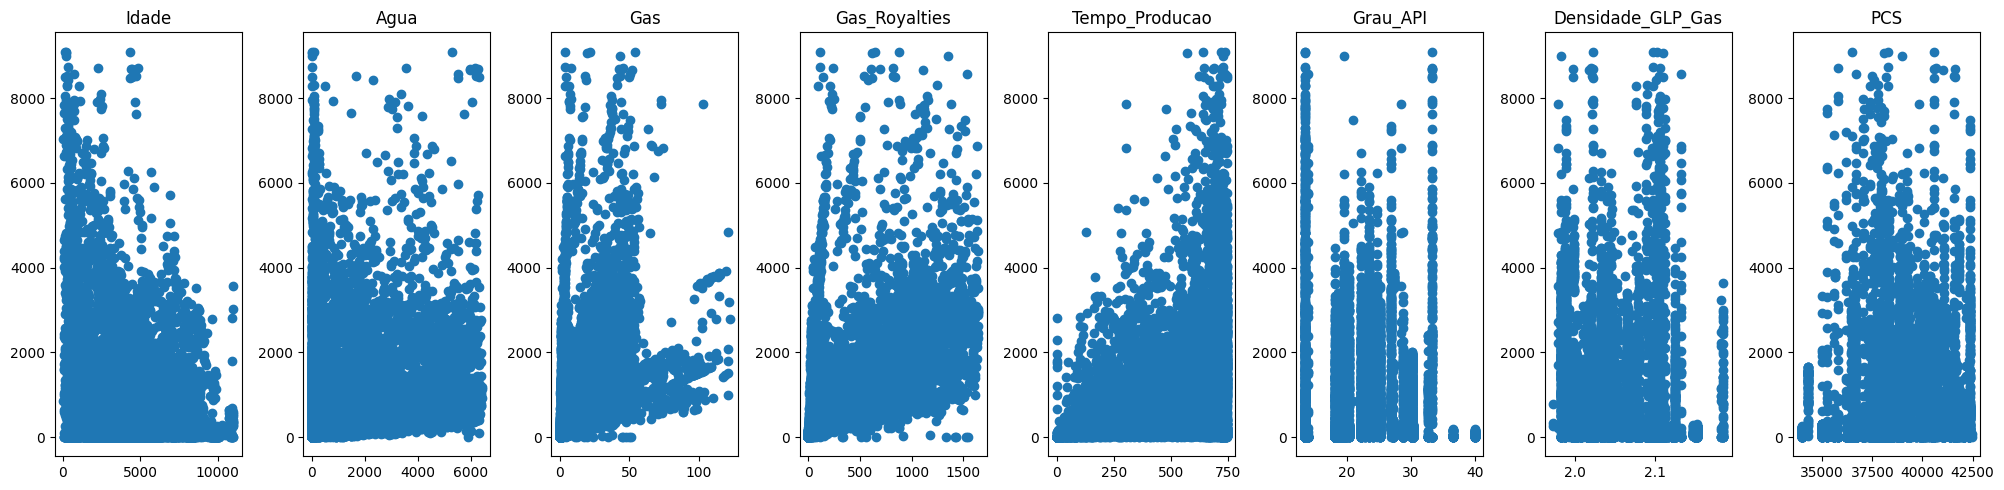

In [13]:
import matplotlib.pyplot as plt

num_features = X_train.columns.size
fig, axes = plt.subplots(nrows=1, ncols=num_features, figsize=(20, 5))

for i, col in enumerate(X_train.columns):
    axes[i].scatter(X_train[col], y_train)
    axes[i].set_title(col)
    
plt.tight_layout()
plt.show()

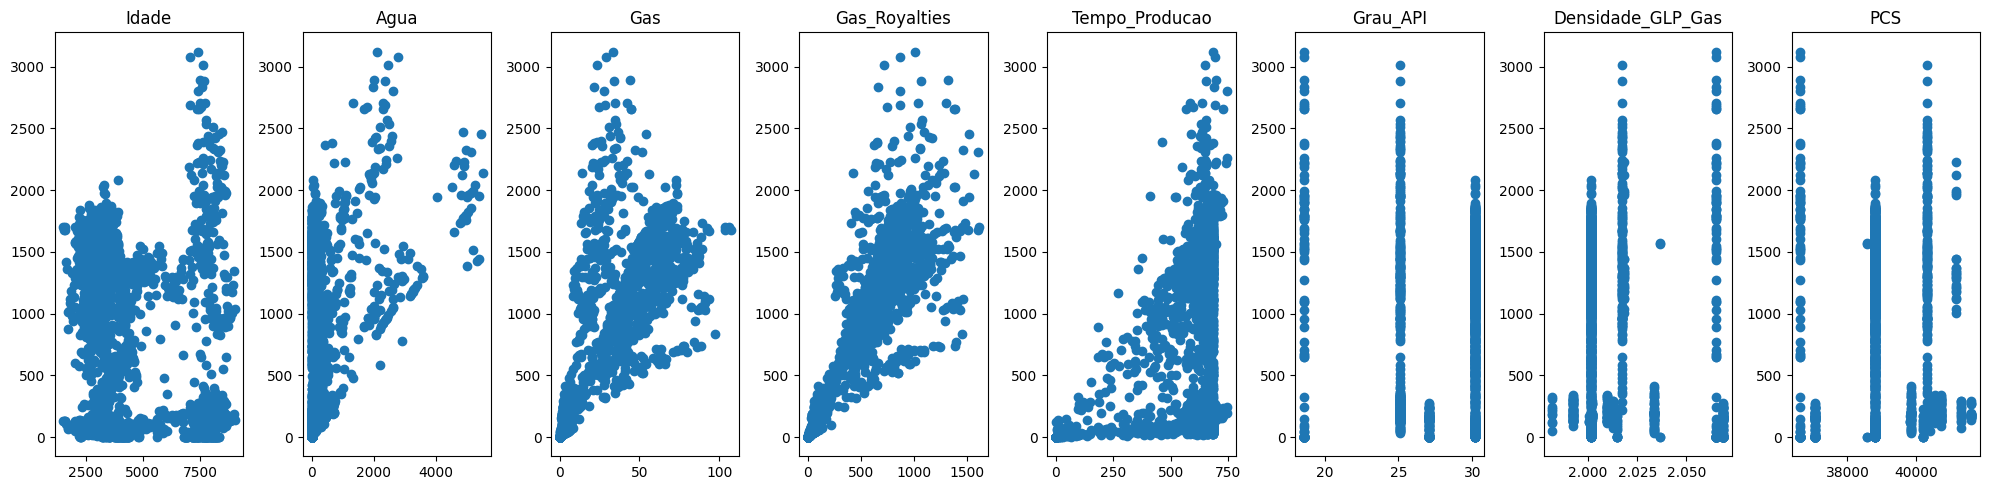

In [14]:
num_features = X_test.columns.size
fig, axes = plt.subplots(nrows=1, ncols=num_features, figsize=(20, 5))

for i, col in enumerate(X_test.columns):
    axes[i].scatter(X_test[col], y_test)
    axes[i].set_title(col)
    
plt.tight_layout()
plt.show()

# Evaluate Methods

In [15]:
results_df = pd.DataFrame()

def evaluate_and_record(model_name, model, X_train, y_train, X_test, y_test, best_params=None):
    global results_df
    
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    
    y_pred_treino = model.predict(X_train)
    y_pred_teste = model.predict(X_test)
    
    rmse_treino = np.sqrt(mean_squared_error(y_train, y_pred_treino))
    r2_treino = r2_score(y_train, y_pred_treino)
    mae_treino = mean_absolute_error(y_train, y_pred_treino)
    
    rmse_teste = np.sqrt(mean_squared_error(y_test, y_pred_teste))
    r2_teste = r2_score(y_test, y_pred_teste)
    mae_teste = mean_absolute_error(y_test, y_pred_teste)
    
    new_row = {
        'Modelo': model_name,
        'R2 Treino': r2_treino,
        'R2 Teste': r2_teste,
        'RMSE Treino': rmse_treino,
        'RMSE Teste': rmse_teste,
        'MAE Treino': mae_treino,
        'MAE Teste': mae_teste,
        'Tempo (segundos)': training_time,
        'Hyperparametros': str(best_params) if best_params else 'N/A'
    }
    
    results_df = pd.concat([results_df, pd.DataFrame([new_row])], ignore_index=True)
    return model

In [16]:
def record_gridsearch_details(grid_search_object, model_prefix):
    global results_df
    
    results = pd.DataFrame(grid_search_object.cv_results_)
    
    for index, row in results.iterrows():
        mean_r2_cv = row['mean_test_score']
        
        mean_fit_time = row['mean_fit_time']
        
        model_name_detail = f"{model_prefix} - Combinacao {index + 1}"
        
        new_row = {
            'Modelo': model_name_detail,
            'R2 Teste': mean_r2_cv,
            'RMSE Teste': np.nan,
            'Tempo (s)': mean_fit_time,
            'Detalhes': f"Combin. Testada (Rank: {row['rank_test_score']})",
            'Hyperparametros': str(row['params'])
        }
        
        results_df = pd.concat([results_df, pd.DataFrame([new_row])], ignore_index=True)

# LinearRegression

In [17]:
model = LinearRegression()
evaluate_and_record("Regressao Linear", model, X_train_scaled, y_train, X_test_scaled, y_test)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Ridge

In [18]:
alphas = np.logspace(-4, 2, 150)

scoring_metric = 'neg_mean_squared_error'
cv=3
ridge_model = Ridge(random_state=42)
grid_search_ridge = GridSearchCV(
    estimator=ridge_model,
    param_grid={'alpha': alphas},
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)

grid_search_ridge.fit(X_train_scaled, y_train)

best_alpha_ridge = grid_search_ridge.best_params_['alpha']
best_ridge_model = grid_search_ridge.best_estimator_

Fitting 3 folds for each of 150 candidates, totalling 450 fits


In [19]:
evaluate_and_record('Ridge Otimo', best_ridge_model, X_train_scaled, y_train, X_test_scaled, y_test, best_alpha_ridge)

,alpha,np.float64(18.843769586593098)
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,42


# Lasso

In [20]:
lasso_model = Lasso(random_state=42, max_iter=2000) 
grid_search_lasso = GridSearchCV(
    estimator=lasso_model,
    param_grid={'alpha': alphas},
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)

grid_search_lasso.fit(X_train_scaled, y_train)

best_alpha_lasso = grid_search_lasso.best_params_['alpha']
best_lasso_model = grid_search_lasso.best_estimator_

Fitting 3 folds for each of 150 candidates, totalling 450 fits


In [21]:
evaluate_and_record('Lasso Otimo', best_lasso_model, X_train_scaled, y_train, X_test_scaled, y_test, best_alpha_lasso)

,alpha,np.float64(0.5066382636136649)
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,2000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


# Random Forest

In [22]:
from sklearn.ensemble import RandomForestRegressor

In [23]:
rf_model = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid={
        'n_estimators': [1500, 1550, 1600],
        'min_samples_split': range(1, 10, 2),
        'min_samples_leaf': range(1, 10, 2),
        'bootstrap': [True],
    },
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)

grid_search_rf.fit(X_train_scaled, y_train)

best_n_estimators_rf = grid_search_rf.best_params_['n_estimators']
best_min_samples_split_rf = grid_search_rf.best_params_['min_samples_split']
best_min_samples_leaf_rf = grid_search_rf.best_params_['min_samples_leaf']
best_bootstrap_rf = grid_search_rf.best_params_['bootstrap']
best_rf_model = grid_search_rf.best_estimator_

Fitting 3 folds for each of 75 candidates, totalling 225 fits


c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
45 fits failed out of a total of 225.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\PC GAMER\D

In [24]:
evaluate_and_record('Random Forest Otimo', best_rf_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_rf.best_params_)

,n_estimators,1500
,criterion,'squared_error'
,max_depth,None
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# Gradient Boosting

In [25]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from xgboost import XGBRegressor

In [27]:
xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42)
grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid={
        'n_estimators': [2000, 2500, 3000],
        'learning_rate': [.0025, .01, .025, .005],
        'max_depth': [9, 11, 13, 15],
        'subsample': [.7, .75, .8],
    },
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)
grid_search_xgb.fit(X_train_scaled, y_train)

best_n_estimators_xgb = grid_search_xgb.best_params_['n_estimators']
best_max_depth_xgb = grid_search_xgb.best_params_['max_depth']
best_learning_rate_xgb = grid_search_xgb.best_params_['learning_rate']
best_subsample_xgb = grid_search_xgb.best_params_['subsample']
best_xgb_model = grid_search_xgb.best_estimator_

Fitting 3 folds for each of 144 candidates, totalling 432 fits


In [28]:
evaluate_and_record('Gradient Boosting Otimo', best_xgb_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_xgb.best_params_)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


# KNN Regression

In [29]:
from sklearn.neighbors import KNeighborsRegressor

In [30]:
knn_model = KNeighborsRegressor()
grid_search_knn = GridSearchCV(
    estimator=knn_model,
    param_grid={
        'n_neighbors': [3, 5, 7, 9, 11],
        'weights': ['uniform', 'distance'],
        'p': range(1, 6),
        'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
        'leaf_size': [30, 40, 50, 60]
    },
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)

grid_search_knn.fit(X_train_scaled, y_train)
best_n_neighbors_knn = grid_search_knn.best_params_['n_neighbors']
best_weights_knn = grid_search_knn.best_params_['weights']
best_p_knn = grid_search_knn.best_params_['p']
best_algorithm_knn = grid_search_knn.best_params_['algorithm']
best_leaf_size_knn = grid_search_knn.best_params_['leaf_size']
best_knn_model = grid_search_knn.best_estimator_

Fitting 3 folds for each of 800 candidates, totalling 2400 fits


In [31]:
evaluate_and_record('KNN Otimo', best_knn_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_knn.best_params_)

,n_neighbors,5
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,1
,metric,'minkowski'
,metric_params,None
,n_jobs,None


# SVR (Suport Vector Regression)

In [32]:
from sklearn.svm import SVR

In [33]:
svr_model = SVR()
grid_search_svr = GridSearchCV(
    estimator=svr_model,
    param_grid={
        'C': [11000, 12000, 13000, 14000, 15000],
        'epsilon': [.5, 1, 2, 3],
        'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
        'gamma': ['scale', 'auto'],
        'coef0': [0, .1, .2]
    },
    scoring=scoring_metric,
    cv=cv,
    verbose=1,
    n_jobs=-1
)

grid_search_svr.fit(X_train_scaled, y_train)

best_C_svr = grid_search_svr.best_params_['C']
best_epsilon_svr = grid_search_svr.best_params_['epsilon']
best_kernel_svr = grid_search_svr.best_params_['kernel']
best_gamma_svr = grid_search_svr.best_params_['gamma']
best_coef0_svr = grid_search_svr.best_params_['coef0']
best_svr_model = grid_search_svr.best_estimator_

Fitting 3 folds for each of 480 candidates, totalling 1440 fits


KeyboardInterrupt: 

In [ ]:
evaluate_and_record('SVR Otimo', best_svr_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_svr.best_params_)

,kernel,'rbf'
,degree,3
,gamma,'auto'
,coef0,0.0
,tol,0.001
,C,11000
,epsilon,1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


# GridSearch Details

In [ ]:
record_gridsearch_details(grid_search_ridge, "Ridge GridSearch")
record_gridsearch_details(grid_search_lasso, "Lasso GridSearch")
record_gridsearch_details(grid_search_rf, "Random Forest GridSearch")
record_gridsearch_details(grid_search_xgb, "XGBoost GridSearch")
record_gridsearch_details(grid_search_knn, "KNN GridSearch")
record_gridsearch_details(grid_search_svr, "SVR GridSearch")

In [ ]:
results_df

,Modelo,R2 Treino,R2 Teste,RMSE Treino,RMSE Teste,MAE Treino,MAE Teste,Tempo (segundos),Hyperparametros,Tempo (s),Detalhes
0,Regressao Linear,0.561304,5.739941e-01,872.494858,442.938878,538.081770,326.918377,0.003399,N/A,NaN,NaN
1,Ridge Otimo,0.561301,5.734770e-01,872.497556,443.207588,537.816565,327.172434,0.001531,18.843769586593098,NaN,NaN
2,Lasso Otimo,0.561302,5.748020e-01,872.496413,442.518633,537.766758,326.873896,0.003130,0.5066382636136649,NaN,NaN
3,Random Forest Otimo,0.989353,8.571970e-01,135.920762,256.451097,59.133903,153.581584,55.632743,"{'bootstrap': True, 'max_depth': None, 'min_sa...",NaN,NaN
4,Gradient Boosting Otimo,0.999970,8.515971e-01,7.189637,261.431033,5.001127,155.157254,4.826651,"{'learning_rate': 0.025, 'max_depth': 9, 'n_es...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
982,SVR GridSearch - Combinacao 156,NaN,-4.708223e+11,NaN,NaN,NaN,NaN,NaN,"{'C': 11000, 'epsilon': 1, 'gamma': 'scale', '...",2.506500,Combin. Testada (Rank: 156)
983,SVR GridSearch - Combinacao 157,NaN,-9.649677e+05,NaN,NaN,NaN,NaN,NaN,"{'C': 11000, 'epsilon': 1, 'gamma': 'auto', 'k...",47.828210,Combin. Testada (Rank: 89)
984,SVR GridSearch - Combinacao 158,NaN,-2.079898e+05,NaN,NaN,NaN,NaN,NaN,"{'C': 11000, 'epsilon': 1, 'gamma': 'auto', 'k...",25.215046,Combin. Testada (Rank: 1)
985,SVR GridSearch - Combinacao 159,NaN,-4.561144e+05,NaN,NaN,NaN,NaN,NaN,"{'C': 11000, 'epsilon': 1, 'gamma': 'auto', 'k...",30.684473,Combin. Testada (Rank: 55)


In [ ]:
results_df.to_csv('model_comparison_results.csv', index=False)